# 08 基于主成分分析的评价分析

> **模块**：多元分析 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、scipy、scikit-learn

## 1. 问题背景

数据分析中涉及的变量往往较多，且在高维空间中研究样本的分布规律，势必增加分析问题的复杂性。在多数情况下，这些变量彼此之间存在着一定程度甚至相当高程度的相关性，这就使包含在观测数据中的信息在一定程度上有所重叠，正是这种变量间信息的重叠增加了分析问题的复杂性。

主成分分析就是一种通过降维技术把多个原始变量重新组合成少数几个互不相关的主成分（综合变量）的统计方法。这些主成分能够反映原始变量的大部分信息，表示为原始变量的某种线性组合。通常选出的变量要比原始指标的变量少，能解释大部分资料中变异的几个新指标变量，即所谓的主成分，并以此解释数据的综合性指标。


## 2. 学习目标

- 掌握主成分分析基本原理
- 掌握从相关矩阵出发求主成分
- 掌握基于 sklearn 实现主成分分析


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 主成分分析基本原理

在实际问题中，多变量问题是经常会遇到的。变量太多，无疑会增加分析问题的难度与复杂性。主成分分析的原理就是把原来多个变量化为少数几个综合指标的一种统计分析方法，从数学角度来看，这是一种**降维**处理技术。

PCA的主要目标是将特征维度变小，同时尽量减少信息损失。

就是对一个样本矩阵，一是换特征，找一组新的特征来重新表示；二是减少特征，新特征的数目要远小于原特征的数目。

#### 4.1.1 主成分分析（PCA）与线性判别分析（LDA）的区别

- PCA和LDA都是经典的降维算法。PCA是无监督的，也就是训练样本不需要标签；LDA是有监督的，也就是训练样本需要标签。PCA是去除掉原始数据中冗余的维度，而LDA是寻找一个维度，使得原始数据在该维度上投影后不同类别的数据尽可能分离开来。
- PCA是去掉原始数据冗余的维度，LDA是选择一个最佳的投影方向，使得投影后相同类别的数据分布紧凑，不同类别的数据尽量相互远离。
- LDA最多可以降到k-1维（k是训练样本的类别数量，k-1是因为最后一维的均值可以由前面的k-1维的均值表示），PCA没有这个限制。

> *原稿配图未随 notebook 保存，此处暂缺。*

#### 4.1.2 主成分分析思想

**PCA思想**：一个中心，两个基本点。
- **一个中心**：原始特征空间的重构（即把线性相关的特征重构为线性无关的特征）；
- **两个基本点**：最大投影方差、最小重构距离，这两个点其实说的是一个事情（最大投影方差：找到一个投影的方向，使得样本在这个方向上的投影方差最大，即投影点应很分散；最小重构距离：样本投影之后，能根据投影将样本重构回去，而重构的代价应尽量小，投影越分散代价越小）

> *原稿配图未随 notebook 保存，此处暂缺。*

例如上图二维数据，降维成为一维，就需要寻找一个方向，并把原始样本点映射到这个方向上。

如上图，我们得到两个方向，那么选择哪个方向能不损失大部分信息呢？

**在新映射的方向上每个数据的映射点方差尽可能大。**因为方差大的数据所包含的信息量越大。并且投影误差小，重构代价小。

#### 4.1.3 主成分分析基本步骤

假设有 $n$ 个研究对象，$m$ 个指标变量 $x_1, x_2, \ldots, x_m$，第 $i$ 个对象第 $j$ 个指标取值为 $a_{ij}$，则构成数据矩阵 $A = (a_{ij})_{n \times m}$。

1. 对原来的 $m$ 个指标进行标准化，得到标准化的指标变量：

$$
b_{ij} = \frac{a_{ij} - \mu_j}{s_j}

$$
其中 $i = 1, 2, \ldots, n$，$j = 1, 2, \ldots, m$，$ \mu_j $ 和 $ s_j $ 分别是样本的均值和标准差，得到标准化后的数据矩阵 $B = (b_{ij})_{n \times m}$。

2. 根据标准化的数据矩阵 $B$ 求出相关系数矩阵 $R = (r_{ij})_{m \times m}$。
3. 计算相关系数矩阵 $R$ 的特征值 $ \lambda_1 \geq \lambda_2 \geq \ldots \geq \lambda_m $ 及对应的标准正交化特征向量 $ u_1, u_2, \ldots, u_m $，其中 $ u_j = [u_{1j}, u_{2j}, \ldots, u_{mj}]^T $，由特征向量组成 $m$ 个新的指标变量：

$$
\begin{cases}
F_1 = u_{11}x_1 + u_{21}x_2 + \ldots + u_{m1}x_m\\
F_2 = u_{12}x_1 + u_{22}x_2 + \ldots + u_{m2}x_m\\
\vdots \\
F_m = u_{1m}x_1 + u_{2m}x_2 + \ldots + u_{mm}x_m\\
\end{cases}

$$
上式中 $F_1$ 是第 1 主成分，$F_2$ 是第 2 主成分，$\ldots$，$F_m$ 是第 $m$ 主成分。

4. 计算主成分贡献率及累计贡献率，主成分 $F_j$ 的贡献率为 $ \omega_j $：

$$
\omega_j = \frac{\lambda_j}{\sum_{k=1}^{m} \lambda_k}, \quad j = 1, 2, \ldots, m

$$
前 $i$ 个主成分的累计贡献率为：

$$
\frac{\sum_{k=1}^{i} \lambda_k}{\sum_{k=1}^{m} \lambda_k}

$$
一般取累计贡献率达 85\% 以上的特征值 $ \lambda_1, \lambda_2, \ldots, \lambda_k $ 所对应的第 1、第 2、\ldots、第 $k \, (k \leq m)$ 主成分。

### 4.2 老年病科医疗质量与效率的评价分析

通过对某医院老年病科2017到2022年的医疗工作质量进行综合评价，为医院和上级部门提供客观、科学的分析管理依据。对这六年间的反映医疗质量和运行效率的指标应用主成分分析法进行统计分析，对这六年的医院老年病科医疗工作做出定量综合评价。

#### 4.2.1 数据导入

本次实验数据来自某市三甲医院老年病科2017-2022年填报的医疗质量统计表。

选择其中常用的5项反映运行效率的指标：
- 门急诊人次$x_1$
- 出院人次$x_2$
- 平均住院日（天）$x_3$
- 床位使用率（%）$x_4$
- 病床周转率（%）$x_5$

5项反映医疗质量的指标：
- 高龄（≥80岁）手术人次$x_6$
- 呼吸机及血液滤过应用天数$x_7$
- 病死率（%）$x_8$
- 死亡患者平均年龄$x_9$
- 出院均次费用$x_{10}$

以上指标$x_3、x_8、x_{10}$属于逆向指标，将其原始数据$x$转化为$100/x$，将逆向指标转化为相对数正向指标。

数据保存在 `../data/pca_data.xlsx` 文件中


In [1]:
import numpy as np, os, pandas as pd, matplotlib.pyplot as plt
plt.rc('font',family="SimHei")
plt.rc('axes',unicode_minus=False)
data = pd.read_excel(os.path.join("..","data", "pca_data.xlsx"))
data

,年份,门急诊人次 (x_1),出院人次 (x_2),平均住院日（天） (x_3),床位使用率（%） (x_4),病床周转率（%） (x_5),高龄（≥80岁）手术人次 (x_6),呼吸机及血液滤过应用天数 (x_7),病死率（%） (x_8),死亡患者平均年龄 (x_9),出院均次费用 (x_{10})
0,2017年,10000,5000,7,85,30,200,150,5.0,78,12000
1,2018年,11000,5200,6,80,32,210,160,6.0,79,12500
2,2019年,12000,5400,8,87,28,220,170,4.5,80,13000
3,2020年,13000,5800,5,86,35,230,180,5.0,81,13500
4,2021年,14000,6000,7,90,33,240,190,4.7,82,14000
5,2022年,15000,6200,6,88,31,250,200,5.2,83,14500


#### 4.2.2 从相关矩阵出发求主成分

##### 4.2.2.1 数据标准化

In [2]:
from scipy.stats import zscore
print(data.dtypes, data.isnull().sum(), sep='\n')
data = data.dropna()
data_sd_t = zscore(data.iloc[:, 1:]).T
data_sd_t

年份                     object
门急诊人次 (x_1)             int64
出院人次 (x_2)              int64
平均住院日（天） (x_3)          int64
床位使用率（%） (x_4)          int64
病床周转率（%） (x_5)          int64
高龄（≥80岁）手术人次 (x_6)      int64
呼吸机及血液滤过应用天数 (x_7)      int64
病死率（%） (x_8)          float64
死亡患者平均年龄 (x_9)          int64
出院均次费用 (x_{10})         int64
dtype: object
年份                    0
门急诊人次 (x_1)           0
出院人次 (x_2)            0
平均住院日（天） (x_3)        0
床位使用率（%） (x_4)        0
病床周转率（%） (x_5)        0
高龄（≥80岁）手术人次 (x_6)    0
呼吸机及血液滤过应用天数 (x_7)    0
病死率（%） (x_8)          0
死亡患者平均年龄 (x_9)        0
出院均次费用 (x_{10})       0
dtype: int64


,0,1,2,3,4,5
门急诊人次 (x_1),-1.463850,-0.878310,-0.292770,0.292770,0.878310,1.463850
出院人次 (x_2),-1.388730,-0.925820,-0.462910,0.462910,0.925820,1.388730
平均住院日（天） (x_3),0.522233,-0.522233,1.566699,-1.566699,0.522233,-0.522233
床位使用率（%） (x_4),-0.321634,-1.929803,0.321634,0.000000,1.286535,0.643268
病床周转率（%） (x_5),-0.676481,0.225494,-1.578457,1.578457,0.676481,-0.225494
高龄（≥80岁）手术人次 (x_6),-1.463850,-0.878310,-0.292770,0.292770,0.878310,1.463850
呼吸机及血液滤过应用天数 (x_7),-1.463850,-0.878310,-0.292770,0.292770,0.878310,1.463850
病死率（%） (x_8),-0.140372,1.965215,-1.193166,-0.140372,-0.772049,0.280745
死亡患者平均年龄 (x_9),-1.463850,-0.878310,-0.292770,0.292770,0.878310,1.463850
出院均次费用 (x_{10}),-1.463850,-0.878310,-0.292770,0.292770,0.878310,1.463850


##### 4.2.2.2 计算相关矩阵和相关矩阵的特征值、特征向量

In [3]:
np.set_printoptions(suppress=True, linewidth=100)  # 设置打印选项，不显示科学计数法，每行字符数为100 #precision=4,
cor_mat = np.corrcoef(data_sd_t.T) # 计算相关矩阵
eig, vec = np.linalg.eig(cor_mat) # 计算特征值和特征向量
print('相关矩阵：\n', cor_mat, '\n特征值：', eig, '\n特征向量：\n', vec)

相关矩阵：
 [[ 1.          0.35985959  0.38382152 -0.59058529 -0.4535584  -0.91400615]
 [ 0.35985959  1.         -0.51473891  0.02638756 -0.95995908 -0.44333436]
 [ 0.38382152 -0.51473891  1.         -0.8501837   0.32269477 -0.14821599]
 [-0.59058529  0.02638756 -0.8501837   1.          0.2118439   0.29702812]
 [-0.4535584  -0.95995908  0.32269477  0.2118439   1.          0.42245899]
 [-0.91400615 -0.44333436 -0.14821599  0.29702812  0.42245899  1.        ]] 
特征值： [ 2.94456214  2.28714759  0.71974508  0.04850408 -0.          0.00004112] 
特征向量：
 [[ 0.52982638  0.18465152  0.32109526  0.66148954  0.37447609 -0.06545918]
 [ 0.39865031 -0.459777   -0.23693734 -0.40969787  0.52703071 -0.35767306]
 [ 0.10509918  0.64117171 -0.16782096 -0.37842087  0.42981392  0.47089996]
 [-0.32556284 -0.46982937  0.50423676 -0.02439868  0.39285975  0.51388755]
 [-0.44584011  0.34785065  0.4354702  -0.17292009  0.28353334 -0.61668445]
 [-0.49452152 -0.04084184 -0.60721137  0.46997897  0.40315797 -0.04072078]]


##### 4.2.2.3 计算主成分的贡献率及累计贡献率

In [4]:
total = eig.sum()
contrib = eig / total
ac = np.cumsum(contrib)

for i in range(len(eig)):
    print(f'第{i+1}主成分的贡献率：{contrib[i]:.4f}，前{i+1}个主成分的累计贡献率：{ac[i]:.4f}')

第1主成分的贡献率：0.4908，前1个主成分的累计贡献率：0.4908
第2主成分的贡献率：0.3812，前2个主成分的累计贡献率：0.8720
第3主成分的贡献率：0.1200，前3个主成分的累计贡献率：0.9919
第4主成分的贡献率：0.0081，前4个主成分的累计贡献率：1.0000
第5主成分的贡献率：-0.0000，前5个主成分的累计贡献率：1.0000
第6主成分的贡献率：0.0000，前6个主成分的累计贡献率：1.0000


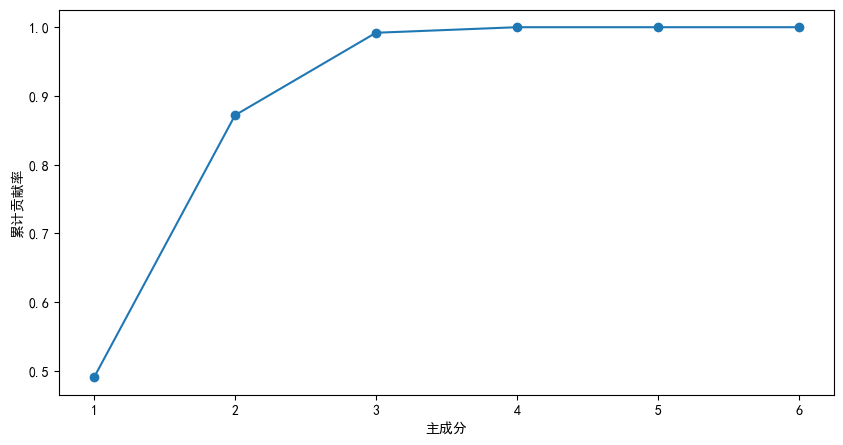

In [5]:

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(ac) + 1), ac, marker='o')
plt.xticks(range(1, len(ac) + 1))
plt.xlabel('主成分')
plt.ylabel('累计贡献率')
#plt.grid(True)
plt.show()

主成分个数提取原则为主成分对应的特征值大于 1 的前 $m$ 个主成分。

特征值在某种程度上可以被看成是表示主成分影响力度大小的指标，如果特征值小于 1，说明该成分的解释力度还不如直接引入一个原变量的平均解释力度大。

前二主成分贡献率分别为 76.33\% 和 15.12\%，因此前两个主成分累计贡献率已达 91.46\%，并且前三主成分特征值均大于 1，所以选取前两个主成分。

$$
\begin{cases}
F_1 = 0.35x_1 + 0.3256x_2 + 0.2517x_3 + 0.2179x_4 + 0.3555x_5 - 0.3426x_6 - 0.3364x_7 + 0.2866x_8 - 0.3464x_9 + 0.3183x_{10} \\
F_2 = 0.071x_1 - 0.0421x_2 - 0.5676x_3 + 0.5920x_4 + 0.0675x_5 - 0.0792x_6 - 0.0929x_7 + 0.4299x_8 + 0.11x_9 - 0.3222x_{10} \\
\end{cases}

$$

#### 4.2.3 sklearn 求解

使用 scikit-learn 库中的 PCA 类可以实现 PCA 主成分分析。

`sklearn.decomposition.PCA(n_components=None, *, copy=True, whiten=False, svd_solver='auto', tol=0.0, iterated_power='auto', random_state=None)`

- **n_components**：整数型或浮点型，或者为 'mle'。如果没有设定该参数，所有原始维度将保留。`n_components=2` 将提取两个主成分。
- **copy**：布尔型，默认值为 True。如果设置为 False，则传递给 fit 函数的数据将被覆盖。
- **whiten**：布尔型，默认为 False。是否消除矢量之间的相关性。
- **svd_solver**：{'auto', 'full', 'arpack', 'randomized'}，默认值为 'auto'。运行不同的求解器，'auto' 是自动设定，'full' 是求解出全部特征值，'arpack' 是求解出 `n_components` 个特征值。
- **tol**：浮点型，默认值为 0.0。设定特征值的公差范围。
- **iterated_power**：整数型，或者 'auto'，默认值为 'auto'。迭代的次数。
- **random_state**：整数型、RandomState 实例或 None，默认值为 None。当使用 'arpack' 或 'randomized' 求解器时使用。在多个函数调用之间传递 int 以获得可重现的结果。

In [6]:
from sklearn.decomposition import PCA
# 创建模型
model=PCA()
# 放入未标准化的数据训练模型
model.fit(data.values[:,1:])
print("特征值为：",model.explained_variance_)
print("各主成分的贡献率：",model.explained_variance_ratio_)
print("奇异值为：",model.singular_values_)
print("各主成分的系数（每一行是一个主成分）：\n",model.components_) 

特征值为： [4597099.02230983    2615.09596662       7.75648291       0.4431106        0.0527967
       0.        ]
各主成分的贡献率： [0.99942967 0.00056853 0.00000169 0.0000001  0.00000001 0.        ]
奇异值为： [4794.31904566  114.3480644     6.22755285    1.48847339    0.51379325    0.        ]
各主成分的系数（每一行是一个主成分）：
 [[ 0.87254101  0.21951272 -0.00012629  0.00109756  0.00037886  0.00872541  0.00872541 -0.00005982
   0.00087254  0.43627051]
 [-0.19617851  0.97479639 -0.01278191  0.00484104  0.03833951 -0.00196179 -0.00196179  0.00014725
  -0.00019618 -0.09808926]
 [-0.00328138  0.01265459  0.25902565  0.87756618 -0.36654586 -0.00003281 -0.00003281 -0.16808877
  -0.00000328 -0.00164069]
 [ 0.00555343 -0.03019069  0.36037738  0.24608674  0.89262592  0.00005553  0.00005553 -0.10880435
   0.00000555  0.00277672]
 [-0.00245924  0.01353962  0.6377688  -0.10200771 -0.13736141 -0.00002459 -0.00002459  0.75085707
  -0.00000246 -0.00122962]
 [-0.44731122  0.00004043  0.00139819 -0.00088552 -0.00048936  0.02844765 

PCA函数使用协方差矩阵作的主成分分析。
比较计算结果，可以发现，从协方差矩阵出发求得的主成分的贡献率与从相关矩阵出发求得的主成分的贡献率存在明显差异。事实上，原始变量方差之间的差异越大，贡献率的差异也越明显，这说明数据标准化后的结论完全可能发生很大的变化，因此标准化并不是无关紧要的。

所以接下来我们使用标准化后的数据训练模型。

In [7]:
# 创建模型
model=PCA(n_components=2)
# 放入标准化的数据训练模型
model.fit(data_sd_t)
print("特征值为：",model.explained_variance_)
print("各主成分的贡献率：",model.explained_variance_ratio_)
print("奇异值为：",model.singular_values_)
print("各主成分的系数（每一行是一个主成分）：\n",model.components_) 

特征值为： [1.8157883  1.54917375]
各主成分的贡献率： [0.47721399 0.40714404]
奇异值为： [4.04253567 3.73397426]
各主成分的系数（每一行是一个主成分）：
 [[ 0.3806184   0.6981034  -0.15423695 -0.11310808 -0.37380829 -0.43756847]
 [ 0.37495925 -0.27924999  0.64299399 -0.54269696  0.06670038 -0.26270667]]


使用numpy库自行编写的PCA主成分分析的主成分的系数与PCA函数的结果可能会相差一个负号（PCA函数自动从大到小排序特征值），因为特征向量乘以-1以后仍然为特征向量。

In [8]:
# 获得降维后数据列
pca_data = model.transform(data_sd_t) 
pca_data

array([[-0.75423096, -0.31812392],
       [-0.73669769, -0.45551986],
       [ 1.17596147,  3.02990406],
       [-0.90871881,  1.20053457],
       [ 1.18355298, -1.42521711],
       [-0.75423096, -0.31812392],
       [-0.75423096, -0.31812392],
       [ 3.05705685, -0.75908209],
       [-0.75423096, -0.31812392],
       [-0.75423096, -0.31812392]])

In [9]:
# 标准化后数据乘以主成分特征向量得到的就是降维后的数据
data_sd_t@model.components_.T

,0,1
门急诊人次 (x_1),-2.127132,-0.976730
出院人次 (x_2),-2.109599,-1.114126
平均住院日（天） (x_3),-0.196940,2.371298
床位使用率（%） (x_4),-2.281620,0.541928
病床周转率（%） (x_5),-0.189349,-2.083824
高龄（≥80岁）手术人次 (x_6),-2.127132,-0.976730
呼吸机及血液滤过应用天数 (x_7),-2.127132,-0.976730
病死率（%） (x_8),1.684155,-1.417689
死亡患者平均年龄 (x_9),-2.127132,-0.976730
出院均次费用 (x_{10}),-2.127132,-0.976730


得到降维后的数据根据其主成分贡献率得到6年的综合得分。

In [10]:
# 得到降维后的两个主成分数据，分别乘以两个主成分的贡献率得到综合得分
rate = model.explained_variance_ratio_.reshape(2,1)
score = pca_data.dot(rate).reshape(1,-1)
print("每年评价的得分为：",score) 
index  = score.argsort()+2017 
print("从低到高年份的编号排序为：",index[0])

每年评价的得分为： [[-0.48945182 -0.53702464  1.79479265  0.05513716 -0.01546061 -0.48945182 -0.48945182  1.14981454
  -0.48945182 -0.48945182]]
从低到高年份的编号排序为： [2018 2017 2025 2026 2022 2023 2021 2020 2024 2019]


以上结果说明，2017-2022这六年老年病科按照效率评价和医疗质量方面是逐年上升的。


### 4.3 协方差特征值法

> 来源：教材参考实现《数学建模算法与应用》10.2 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

- 函数原型: sklearn.decomposition.PCA(n_components=None, copy=True, whiten=False)
- 官方文档: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html?highlight=pca#sklearn.decomposition.PCA
- 相关说明: https://www.jianshu.com/p/8642d5ea5389

[[ 0.41724458  0.90879423]
 [ 0.90879423 -0.41724458]]

[[1.16076484 0.        ]]
[[ 0.69085661 -0.43769496]]

[0.97468327 0.02531673]


Text(0.5, 1.0, 'Dimensionality Reduced')

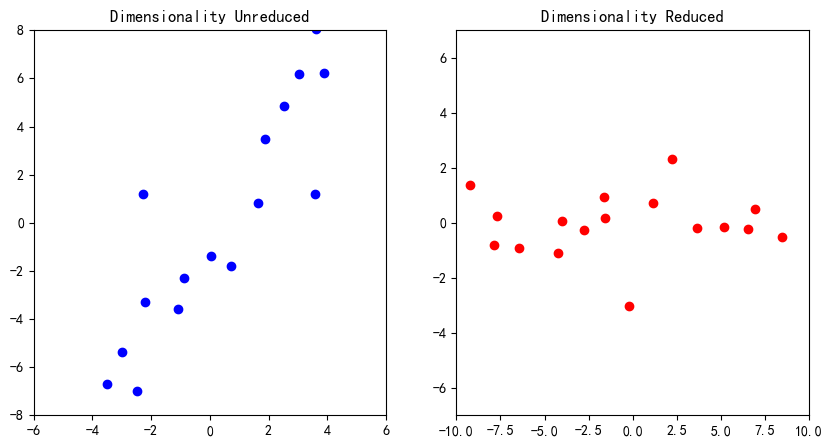

In [11]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

np.random.seed(0)

X = np.linspace(-5, 5, 20)
X = X.reshape((X.shape[0], 1))
X = np.concatenate((X, 2*X), axis=1)
X = X + np.random.normal(loc=0, scale=1, size=X.shape)


# 计算关联系数矩阵
# np.cov中的bias=False表示除以N-1而不是N
R = np.cov(X.T, bias=False)
# print(R)
eigenvalues, eigenvectors = np.linalg.eig(R)
order = eigenvalues.argsort()[::-1]
eigenvalues_order = eigenvalues[order]
eigenvectors = eigenvectors[order]
eigenvalues[1] = -eigenvalues[1]

# PCA训练器
pca = PCA(n_components=2, copy=True, whiten=False)
# 训练并降维
pca.fit(X)
x0 = [pca.components_[:, 0]]
newX = pca.transform(x0)

print(pca.components_)
print()
print(np.matmul(x0, pca.components_*eigenvalues))
print(newX)
# 将降维后数据逆变换回原数据
pca.inverse_transform(newX)
# 各个特征的方差百分比
print()
print(pca.explained_variance_ratio_)
#print(pca.explained_variance_ratio_) # 即特征值百分比
#print(pca.explained_variance_) # 即特征值

newX = pca.transform(X)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(X[:,0], X[:, 1], color='b')
plt.xlim(xmin=-6, xmax=6)
plt.ylim(ymin=-8, ymax=8)
plt.title('Dimensionality Unreduced')
plt.subplot(1, 2, 2)
plt.scatter(newX[:,0], newX[:, 1], color='r')
plt.xlim(xmin=-10, xmax=10)
plt.ylim(ymin=-7, ymax=7)
plt.title('Dimensionality Reduced')

## 5. 小结

本次实验介绍了主成分分析的思路和一般步骤，并且通过一个实例使用从相关矩阵和sklearn库实现主成分分析。

通过本次实验需要掌握以下内容：
- 掌握主成分分析基本原理
- 掌握从相关矩阵出发求主成分
- 掌握基于sklearn实现主成分分析
